# LLM-Scorervergleich: ergänzende Prüfung der QA-Klassifikation

## Eingaben und Ausgaben

Nach der einmaligen Vorbereitung mit `python 05_analyze.py --prepare` genügt **Run All**.
Die folgende Zelle zeigt Daten, Vorgängertabellen und neue Ausgaben. `DATA_DIR` und
`OUTPUT_DIR` dürfen auf eigene absolute Verzeichnisse zeigen. `TABLES` liest standardmäßig
die vorbereiteten historischen Tabellen; für selbst neu erzeugte Vorgängertabellen
kann hier `OUTPUT_DIR / "tables"` stehen. Eingaben und neue Ausgaben bleiben getrennt.


In [1]:
from pathlib import Path
from faktenretention.paths import PROJECT_ROOT
from faktenretention.notebook_context import setup_notebook
from faktenretention.io import relative_path, sha

# Hier können eigene absolute Daten- und Ausgabeverzeichnisse stehen.
DATA_DIR = PROJECT_ROOT / "data/prepared"
OUTPUT_DIR = PROJECT_ROOT / "results/notebooks"
# Historische Vorgängertabellen; für eigene Neuberechnungen OUTPUT_DIR / "tables" einsetzen.
TABLES = DATA_DIR / "tables"
setup_notebook(DATA_DIR, OUTPUT_DIR)
OUT = OUTPUT_DIR / "tables/12_llm_scorervergleich"
FIG = OUTPUT_DIR / "figures/12_llm_scorervergleich"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
print("Eingaben:", DATA_DIR / "llm")
print("Vorgängertabellen:", TABLES)
print("Neue Tabellen:", OUT)
print("Neue Grafiken:", FIG)


Eingaben: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/llm
Vorgängertabellen: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/tables
Neue Tabellen: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/tables/12_llm_scorervergleich
Neue Grafiken: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/figures/12_llm_scorervergleich


## Ergebnisüberblick

- Drei hochgeladene LLM-Ausgaben liefern **600 Urteile über dieselben 200 QA-Fälle**. Frühere Mock-Dateien werden nicht verwendet.
- Auf **138 Fällen mit eindeutiger Retained-/Lost-/Unsupported-Mehrheit** stimmt der kalibrierte Scorer in **113 Fällen (81,9 %)** überein. Das 95%-Artikel-Cluster-Intervall beträgt **75,8–87,6 %**.
- **60 Sonderfallmehrheiten und zwei Gleichstände** bleiben außerhalb dieses Drei-Klassen-Vergleichs; die Abdeckung beträgt 69 % der Stichprobe.
- Alle drei LLMs stimmen in **166/200 Fällen (83 %)** vollständig überein; nominales Alpha über alle vier Kategorien beträgt **0,824**.
- Dies ist eine **LLM-basierte Zusatzanalyse, keine Human Validation**. Modellversionen, vollständige Prompts und unabhängig überprüfbare Laufprotokolle fehlen. Die gezielte Stichprobe erlaubt keine allgemeine Genauigkeitsschätzung für das Hauptexperiment.

Die folgenden Zellen berechnen diese Werte aus den mitgelieferten Originaldateien neu und gleichen sie mit dem vorherigen Auswertungslauf ab.

## 1. Anlass und Fragestellungen

Die Masterarbeit untersucht Faktenretention unter progressiver Kompression von Nachrichtenartikeln. Die QA-Pipeline erzeugt Antworten auf feste Fragen aus dem Ausgangsartikel und ordnet sie lexikalisch als Retained, Lost oder referenzabweichend ein. Inhaltlich korrekte Paraphrasen können beim Antwortvergleich scheitern; umgekehrt beweist lexikalische Ähnlichkeit keine Unterstützung durch die Zusammenfassung.

Notebook 09 untersucht interne Plausibilität bei Lead-k, Notebook 10 die Robustheit gegenüber hypothetischen Messfehlern und Notebook 11 die Rolle der tatsächlichen Wortlängen. Hier wird ergänzend gefragt:

1. Wie stark stimmen die drei LLM-Bewertenden miteinander überein?
2. Wie stark stimmen der kalibrierte QA-Scorer und die rekonstruierte ursprüngliche Regel mit derselben LLM-Mehrheit überein?
3. Welche Fälle weichen ab und wie stabil sind die Werte bei strengerer Konsensbildung?

Die Bewertung durch mehrere Modellfamilien ist keine unabhängige menschliche Referenz. Gemeinsame Trainingsdaten, ähnliche Fehler oder ähnliche Prompts können korrelierte Urteile begünstigen. Die einzelnen Modelle werden deshalb nicht anhand einer Mehrheit, in der ihre eigene Stimme enthalten ist, als besser oder schlechter gerankt.

## 2. Daten und festgelegte Bewertungsregeln

Grundlage sind 200 Fälle aus allen 100 Artikeln des archivierten Hauptexperiments `aktuell_20260930`: sechs Methoden, vier Zielstufen, 20 kanonische Fakten je Artikel. Die Auswahl ist gezielt nach vorläufigen Scorerlabels quotiert (80 Retained, 80 Lost, 40 Unsupported) und reichert schwierige Fälle an; Seed 32. Besonders häufig sind kalibrierungsbedingte Labeländerungen und NOT_FOUND bei wörtlichen Referenzhinweisen. **Diese Auswahl ist nicht repräsentativ für alle 48.000 QA-Positionen.** Keine rekonstruierbaren Auswahlwahrscheinlichkeiten, daher keine Populationsgewichtung.

Die historischen 60 zur Kalibrierung verwendeten Humanfälle sind ausgeschlossen. Details und Quelldokumentation stehen in `DATA_DIR/llm/METHODIK_3_10.md` und `QUELLENPRUEFUNG.md`.

| Label | Regel |
|---|---|
| retained | Inhaltlich passende Antwort und Unterstützung durch die Zusammenfassung; Paraphrasen zulässig. |
| lost | Information aus dem vollständigen Summary nicht wiederherstellbar **und** QA-Antwort NOT_FOUND. |
| unsupported | Inhaltlich abweichende oder nicht als korrekte Antwort gestützte Antwort; keine automatische Gleichsetzung mit Halluzination. |
| special | NOT_FOUND trotz enthaltener Information, unklare Referenz/Frage, Teilrichtigkeit, Widerspruch oder Unsicherheit. |

### Annahmen und Grenzen

- `human_label` ist lediglich der technische Feldname der hochgeladenen Dateien; die Urteile stammen laut Auftrag von LLMs.
- Maßgeblich ist `human_label`; ein zusätzliches `label=unclear` wird nur als dokumentiertes Alias für `special` akzeptiert, wenn beide inhaltlich übereinstimmen.
- Teilnehmerkennungen dienen hier ausschließlich als Rater-IDs. Modellnamen sind Angaben aus den Dateinamen, keine verifizierten Provider-Versionen.
- Zeitstempel, Bearbeitungszeiten, Öffnungsflags und Revisionslisten dieser modellgenerierten Dateien werden nicht als beobachtetes Browserverhalten interpretiert.
- Sonderfälle zählen bei der Reliabilität als vierte echte Kategorie. Für den Scorervergleich ist eine Hauptklassenmehrheit von mindestens zwei aus drei Stimmen erforderlich. Gleichstände und Sonderfallmehrheiten werden separat ausgewiesen.
- Jev-Vorhersagen für diese 200 Fälle liegen nicht vor. Die ursprüngliche Regel wird nur als zusätzliche historische Vergleichsregel auf denselben Antworten betrachtet.

### 3. Einrichtung: lokale, mitgelieferte Dateien

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
import csv, hashlib, json, math, random, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

sys.dont_write_bytecode = True
BUNDLE = DATA_DIR
DATA = DATA_DIR / "llm"
OUT.mkdir(parents=True, exist_ok=True)
LABELS = ('retained', 'lost', 'unsupported')
HUMAN_LABELS = (*LABELS, 'special')  # historischer Variablenname, hier ausschließlich LLM-Urteile
SCORERS = ('calibrated_scorer_label', 'original_scorer_label')
SEED, BOOTSTRAPS = 32, 10000
COLORS = {'retained':'#0072B2','lost':'#E69F00','unsupported':'#CC79A7','special':'#999999'}
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':180,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_colwidth', 95)
def save_csv(rows, name): pd.DataFrame(rows).to_csv(OUT/name,index=False,encoding='utf-8-sig')
def save_figure(fig, name):
    fig.savefig(FIG/name,bbox_inches='tight')
    plt.show()
    plt.close(fig)


### 4. Eingaben prüfen und an stabilen Fall-IDs verbinden

In [3]:
def strict_json(path):
    def unique(pairs):
        result = {}
        for key, value in pairs:
            if key in result: raise ValueError('Doppelter JSON-Schlüssel: '+key)
            result[key] = value
        return result
    return json.loads(path.read_text(encoding='utf-8-sig'), object_pairs_hook=unique)

manifest = strict_json(DATA/'human_validation_manifest.json')
reference = strict_json(DATA/'referenz_auswertung.json')
cases = strict_json(DATA/'evaluation_cases.json')
expected_ids = {c['case_id'] for c in cases}
assert len(cases) == len(expected_ids) == 200
assert manifest['dataset_id'] == reference['dataset_id']
assert sha(DATA/'evaluation_cases.json') == manifest['file_sha256']['intern/evaluation_cases.json']
files = sorted((DATA/'eingaben').glob('*.json'))
assert len(files) == 3
grouped, source_rows = {}, []
for path in files:
    obj = strict_json(path)
    pid = obj['participant_id']
    cfg = strict_json(DATA/(pid+'.json'))
    assert obj['dataset_id'] == manifest['dataset_id']
    assert pid not in grouped and obj['order'] == cfg['case_ids']
    responses = obj['responses']
    assert len(responses) == 200 and set(responses) == expected_ids
    expected_source = next(s for s in reference['sources'] if s['rater_id'] == pid)
    assert sha(path) == expected_source['sha256']
    for cid, row in responses.items():
        assert row['case_id'] == cid and row['participant_id'] == pid
        assert row['case_order'] == obj['order'].index(cid)+1
        assert row['human_label'] in HUMAN_LABELS
        if 'label' in row:
            assert ('special' if row['label']=='unclear' else row['label']) == row['human_label']
    grouped[pid] = responses
    source_rows.append({'Rater':pid,'Modellangabe':expected_source['model_name_as_supplied'],
        'Urteile':len(responses),'Kommentare':sum(bool(r.get('comment')) for r in responses.values()),
        'SHA-256':sha(path)})
pids = sorted(grouped)
assert sum(len(g) for g in grouped.values()) == 600
source_hashes = {relative_path(p, BUNDLE):sha(p) for p in [*files, DATA/'evaluation_cases.json']}
display(pd.DataFrame(source_rows).drop(columns='SHA-256'))
display(pd.DataFrame([{k:c[k] for k in ['case_id','article_id','method','stage','question','reference_answer','generated_answer']} for c in cases[:3]]))


,Rater,Modellangabe,Urteile,Kommentare
0,participant_01,Gemini_4_Argon_medium,200,0
1,participant_02,Claude_Sonnet_5.5_medium,200,0
2,participant_03,GPT-61_sol_medium,200,65


,case_id,article_id,method,stage,question,reference_answer,generated_answer
0,N00439cf344c7d5bc,12,zero_shot_cot,300,What is trepanation?,drilling a hole into the skull,the practice of drilling holes in the skull
1,N004c78e59842bc36,79,automate_cot,75,Which Apple Watch model lacks a sapphire glass screen?,Sport model,The Sport version
2,N00f5566a8f00af42,11,zero_shot_cot,500,Which Justice wrote a brief dissenting opinion about the failure to grant stays?,Justice Clarence Thomas,NOT_FOUND


### 5. Rechenregeln: Konsens, nominale Übereinstimmung und Drei-Klassen-Metriken

In [4]:
def consensus(votes):
    counts = Counter(votes)
    winners = [k for k,v in counts.items() if v == max(counts.values())]
    unique = len(winners) == 1
    label = winners[0] if unique else None
    majority = unique and counts[label] > len(votes)/2
    return dict(**{f'votes_{k}':counts[k] for k in HUMAN_LABELS},
                absolute_majority=majority, unique_plurality=unique,
                plurality_without_majority=unique and not majority,
                tie=not unique, consensus_label=label,
                three_class_consensus=majority and label in LABELS)

def alpha_nominal(units):
    units = [list(u) for u in units if len(u) >= 2]
    counts = Counter(x for unit in units for x in unit)
    n = sum(counts.values())
    if n < 2:
        return None
    observed = sum((len(u)**2-sum(v*v for v in Counter(u).values()))/(len(u)-1) for u in units)/n
    expected = (n*n-sum(v*v for v in counts.values()))/(n*(n-1))
    return 1-observed/expected if expected else None

def reliability(grouped):
    pids = sorted(grouped)
    ids = sorted(grouped[pids[0]])
    units = [[grouped[p][i]['human_label'] for p in pids] for i in ids]
    pairs = []
    for a,b in combinations(pids,2):
        n = sum(grouped[a][i]['human_label']==grouped[b][i]['human_label'] for i in ids)
        pairs.append(dict(participant_a=a,participant_b=b,agreements=n,n=len(ids),agreement=n/len(ids)))
    dist = Counter(v for u in units for v in u)
    return dict(n_cases=len(ids),n_ratings=sum(dist.values()),
        full_agreement_cases=sum(len(set(u))==1 for u in units),
        full_agreement=sum(len(set(u))==1 for u in units)/len(units),
        pairwise_agreement=sum(r['agreements'] for r in pairs)/(3*len(ids)),
        pairs=pairs,krippendorff_alpha_nominal=alpha_nominal(units),
        label_counts={k:dist[k] for k in HUMAN_LABELS},
        label_counts_by_participant={p:{k:sum(grouped[p][i]['human_label']==k for i in ids) for k in HUMAN_LABELS} for p in pids},
        special_rate=dist['special']/(3*len(ids)),
        cases_with_any_special=sum('special' in u for u in units))


In [5]:
def confusion(truth, pred):
    cm = [[0]*3 for _ in range(3)]
    for a,b in zip(truth,pred):
        cm[LABELS.index(a)][LABELS.index(b)] += 1
    return cm

def metrics_cm(cm):
    n = sum(map(sum,cm))
    correct = sum(cm[i][i] for i in range(3))
    per = []
    for i,label in enumerate(LABELS):
        support, predicted, tp = sum(cm[i]),sum(r[i] for r in cm),cm[i][i]
        p = tp/predicted if predicted else 0.0
        r = tp/support if support else None
        f = 2*tp/(support+predicted) if support+predicted else 0.0
        per.append(dict(label=label,support=support,predicted=predicted,precision=p,recall=r,f1=f))
    expected = sum(sum(cm[i])*sum(r[i] for r in cm) for i in range(3))/n**2 if n else None
    accuracy = correct/n if n else None
    return dict(n=n,correct=correct,errors=n-correct,error_rate=1-accuracy if n else None,
        accuracy=accuracy,macro_f1=sum(r['f1'] for r in per)/3 if n else None,
        cohen_kappa=(accuracy-expected)/(1-expected) if n and expected<1 else None,
        class_order=LABELS,confusion_matrix=cm,per_class=per,
        absent_truth_classes=[r['label'] for r in per if not r['support']])

def metrics(truth,pred):
    return metrics_cm(confusion(truth,pred))

def flat_metrics(m):
    out={k:m[k] for k in ('accuracy','macro_f1','cohen_kappa','error_rate')}
    for r in m['per_class']:
        for k in ('precision','recall','f1'):
            out[r['label']+'.'+k]=r[k]
    return out

def percentile(values,q):
    values=sorted(values)
    if not values:
        return None
    k=(len(values)-1)*q
    lo=math.floor(k)
    return values[lo]+(values[math.ceil(k)]-values[lo])*(k-lo)

def interval(values,attempts):
    values=[v for v in values if v is not None]
    return dict(lower=percentile(values,.025),upper=percentile(values,.975),
                valid_replicates=len(values),undefined_replicates=attempts-len(values))


In [6]:
joined = []
for c in cases:
    votes = [grouped[p][c['case_id']]['human_label'] for p in pids]
    joined.append({**c, **consensus(votes), **{p+'_llm_label':v for p,v in zip(pids,votes)}})
primary = [r for r in joined if r['three_class_consensus']]
excluded = [r for r in joined if not r['three_class_consensus']]
agreement = reliability(grouped)
estimates = {s:metrics([r['consensus_label'] for r in primary],[r[s] for r in primary]) for s in SCORERS}
consensus_counts = Counter(r['consensus_label'] or 'tie' for r in joined)
assert len(primary) == reference['consensus']['main_class_majority_cases']
assert dict(consensus_counts) == reference['consensus']['all_four_class_counts']
for s,m in estimates.items():
    for key in ['n','correct','accuracy','macro_f1','cohen_kappa']:
        assert abs(m[key]-reference['scorers_against_llm_majority'][s][key]) < 1e-12
assert abs(agreement['krippendorff_alpha_nominal']-reference['agreement']['krippendorff_alpha_nominal']) < 1e-12
display(pd.DataFrame([{'Konsens':k,'Fälle':consensus_counts.get(k,0)} for k in [*HUMAN_LABELS,'tie']]))
save_csv(joined,'konsens_alle_200.csv')
save_csv(excluded,'ausgeschlossen_sonderfall_oder_gleichstand.csv')


,Konsens,Fälle
0,retained,91
1,lost,38
2,unsupported,9
3,special,60
4,tie,2


## 6. Wie stark stimmen die LLMs überein?

Alle 200 Fälle und alle vier Kategorien gehen ein. Eine hohe Übereinstimmung misst Konsistenz dieser Ausgaben, nicht deren Wahrheit oder Unabhängigkeit.

,retained,lost,unsupported,Sonderfall
Gemini 4 Argon,88,36,16,60
Claude Sonnet 5.5,93,31,9,67
GPT-61 sol,92,43,7,58


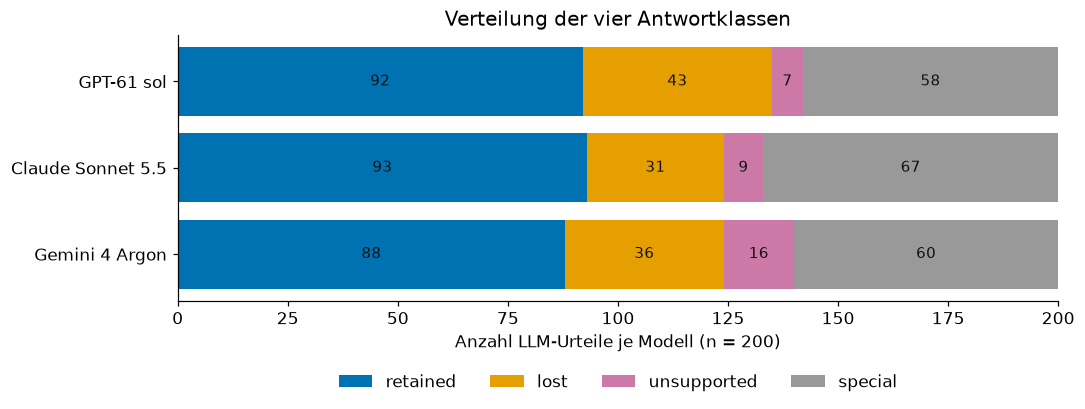

,Rater A,Rater B,Übereinstimmungen,n,Anteil
0,participant_01,participant_02,176,200,0.880
1,participant_01,participant_03,179,200,0.895
2,participant_02,participant_03,175,200,0.875


**Alle drei gleich:** 166/200 (83.0%). **Paarweise gesamt:** 88.3%. **Nominales Alpha:** 0.824.

In [7]:
distribution = pd.DataFrame([{k:sum(r['human_label']==k for r in grouped[p].values()) for k in HUMAN_LABELS} for p in pids],index=pids)
distribution.index = [next(r['Modellangabe'] for r in source_rows if r['Rater']==p).replace('_medium','').replace('_',' ') for p in pids]
display(distribution.rename(columns={'special':'Sonderfall'}))
fig, ax = plt.subplots(figsize=(10,4))
left = np.zeros(3)
for label in HUMAN_LABELS:
    values=distribution[label].to_numpy()
    ax.barh(distribution.index,values,left=left,color=COLORS[label],label=label)
    for i,v in enumerate(values):
        if v >= 7: ax.text(left[i]+v/2,i,str(v),ha='center',va='center',fontsize=10,color='#111111')
    left+=values
ax.set_xlim(0,200); ax.set_xlabel('Anzahl LLM-Urteile je Modell (n = 200)')
ax.set_title('Verteilung der vier Antwortklassen')
ax.legend(ncol=4,loc='upper center',bbox_to_anchor=(0.5,-0.22),frameon=False)
fig.tight_layout(); save_figure(fig,'01_llm_klassenverteilung.png')
display(pd.DataFrame(agreement['pairs']).rename(columns={'participant_a':'Rater A','participant_b':'Rater B','agreements':'Übereinstimmungen','agreement':'Anteil'}))
display(Markdown(f"**Alle drei gleich:** {agreement['full_agreement_cases']}/200 ({agreement['full_agreement']:.1%}). **Paarweise gesamt:** {agreement['pairwise_agreement']:.1%}. **Nominales Alpha:** {agreement['krippendorff_alpha_nominal']:.3f}."))


## 7. Wie stark stimmt der Scorer mit der LLM-Mehrheit überein?

Nur 138 von 200 Fällen haben eine eindeutige Hauptklassenmehrheit. Sonderfälle werden nicht nachträglich Lost oder Unsupported zugeschlagen. Die ursprüngliche Regel ist eine dokumentierte Rekonstruktion auf denselben aktuellen QA-Antworten; sie ist keine neue Jev-Ausgabe. Die Stichprobe reichert gerade Fälle an, bei denen die Kalibrierung relevant ist. Ihr großer Abstand zur ursprünglichen Regel ist deshalb nicht als repräsentativer Populationseffekt zu interpretieren.

In [8]:
def cluster_intervals(rows,repetitions,seed=32):
    if not rows:
        return dict(status='NO_MAIN_CLASS_LLM_MAJORITY')
    articles=sorted({r['article_id'] for r in rows})
    blocks={a:{s:confusion([r['consensus_label'] for r in rows if r['article_id']==a],
                              [r[s] for r in rows if r['article_id']==a]) for s in SCORERS} for a in articles}
    samples={s:defaultdict(list) for s in SCORERS}; differences=[]
    rng=random.Random(seed)
    for _ in range(repetitions):
        weights=Counter(rng.choices(articles,k=len(articles)));point={}
        for scorer in SCORERS:
            cm=[[sum(w*blocks[a][scorer][i][j] for a,w in weights.items()) for j in range(3)] for i in range(3)]
            point[scorer]=flat_metrics(metrics_cm(cm))
            for k,v in point[scorer].items():samples[scorer][k].append(v)
        differences.append(point[SCORERS[0]]['accuracy']-point[SCORERS[1]]['accuracy'])
    return dict(seed=seed,repetitions=repetitions,article_clusters=len(articles),
        method='95% percentile article-cluster bootstrap; paired predictions travel together; conditional on selected cases, observed LLM majority and these three model outputs.',
        scorers={s:{k:interval(v,repetitions) for k,v in vals.items()} for s,vals in samples.items()},
        calibrated_minus_original_accuracy=interval(differences,repetitions))


,Scorer,Richtig,Auswertbar,Accuracy,95% unten,95% oben,Macro-F1,Kappa
0,Kalibriert,113,138,0.8188,0.7578,0.8759,0.7346,0.6852
1,Ursprüngliche Regel,50,138,0.3623,0.2734,0.4552,0.4112,0.2619


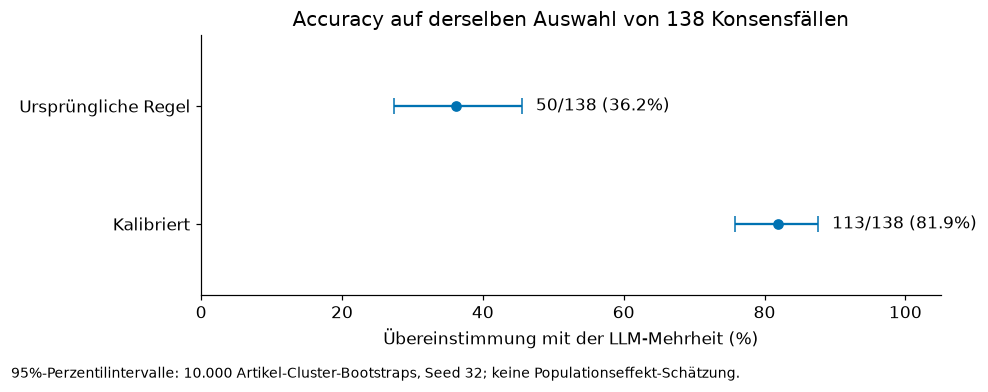

In [9]:
bootstrap = cluster_intervals(primary, BOOTSTRAPS, SEED)
rows=[]
for scorer in SCORERS:
    m=estimates[scorer]; ci=bootstrap['scorers'][scorer]['accuracy']
    expected=reference['article_cluster_bootstrap']['scorers'][scorer]['accuracy']
    assert abs(ci['lower']-expected['lower']) < 1e-12 and abs(ci['upper']-expected['upper']) < 1e-12
    rows.append({'Scorer':'Kalibriert' if scorer.startswith('calibrated') else 'Ursprüngliche Regel',
        'Richtig':m['correct'],'Auswertbar':m['n'],'Accuracy':m['accuracy'],
        '95% unten':ci['lower'],'95% oben':ci['upper'],'Macro-F1':m['macro_f1'],'Kappa':m['cohen_kappa']})
score_table=pd.DataFrame(rows)
display(score_table.round(4))
fig,ax=plt.subplots(figsize=(9,3.4))
for i,row in score_table.iterrows():
    ax.errorbar(row['Accuracy']*100,i,xerr=[[100*(row['Accuracy']-row['95% unten'])],[100*(row['95% oben']-row['Accuracy'])]],fmt='o',color='#0072B2',capsize=5)
    ax.text(row['95% oben']*100+2,i,f"{row['Richtig']}/{row['Auswertbar']} ({row['Accuracy']:.1%})",va='center')
ax.set_yticks(range(2),score_table.Scorer);ax.set_xlim(0,105);ax.set_ylim(-.6,1.6)
ax.set_xlabel('Übereinstimmung mit der LLM-Mehrheit (%)')
ax.set_title('Accuracy auf derselben Auswahl von 138 Konsensfällen')
fig.text(.01,-.03,'95%-Perzentilintervalle: 10.000 Artikel-Cluster-Bootstraps, Seed 32; keine Populationseffekt-Schätzung.',fontsize=9)
fig.tight_layout();save_figure(fig,'02_accuracy_artikelbootstrap.png')
save_csv(rows,'scorervergleich_mit_intervallen.csv')


Die Intervalle ziehen Artikel mit Zurücklegen und übernehmen jeweils sämtliche zugehörigen Fälle und beide Scorerlabels gemeinsam. Sie berücksichtigen die Artikelabhängigkeit, bleiben aber bedingt auf diese gezielte Stichprobe, die beobachtete Konsensmenge und genau diese drei Modellantworten. Prompt-, Lauf- und Modellpopulationseffekte sind nicht abgedeckt.

### Klassenweise Abweichungen und konkrete Fälle

,label,support,predicted,precision,recall,f1
0,retained,91,70,0.971,0.747,0.845
1,lost,38,38,1.000,1.000,1.000
2,unsupported,9,30,0.233,0.778,0.359


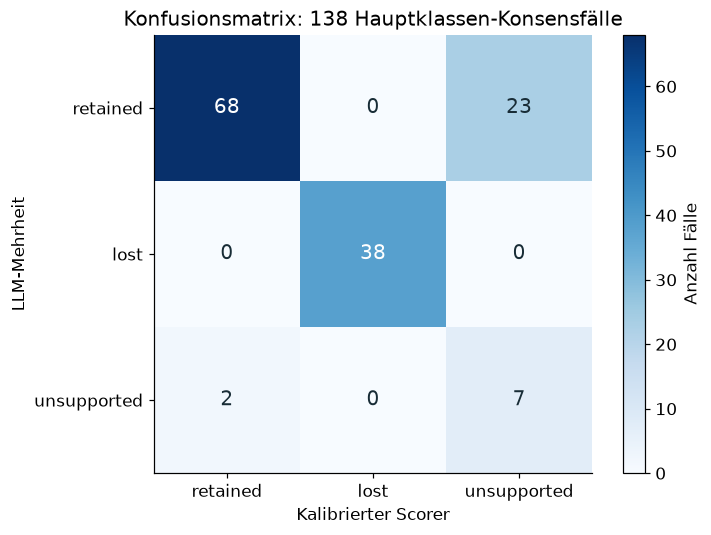

,LLM-Mehrheit,Scorer,Fälle
0,retained,unsupported,23
1,unsupported,retained,2


,case_id,question,reference_answer,generated_answer,consensus_label,calibrated_scorer_label
0,N1c02d6497906f213,What time is the fire thought to have started?,around 7am Friday morning,7 a.m.,retained,unsupported
1,N2a4e01ba70656ef7,How long is the launch window?,20 days,20-day window,retained,unsupported
2,N359c55dba6b67ba4,How many times in its history has the estate been on the market?,third time,three,retained,unsupported
3,N3a905796ba45772d,When did the image of the rules begin to circulate?,two weeks after Islamic State was forced to abandon the Iraqi city of Tikrit,two weeks after ISIS abandoned Tikrit,retained,unsupported
4,N3c0faa66d7afe50b,Who proposed a laser system to be attached to the ISS?,Tokyo researchers,Researchers at Japan’s Riken Institute,retained,unsupported
5,N5b9acf1d5eddb1eb,How much extra annual funding did the party pledge for the NHS?,£12billion a year,£12 billion,retained,unsupported
6,N67cb66900937a6a0,At what depth were the methane vents where the virus was discovered?,"2,800 feet","8,000+ feet",unsupported,retained
7,N6bf84b7590de8e9e,Who is Paul Scialla?,the chief executive of New York development firm Delos,Delos CEO,retained,unsupported
8,N6eeef83f44a25aea,Does Dr Jawad admit to the allegations?,denies all the allegations,No,retained,unsupported
9,N76f44f0641729f63,What has the Supreme Court seemingly become according to the text?,a place for partisan theatrics,a court shaped more by partisanship than legal reasoning,retained,unsupported


In [10]:
cal=estimates['calibrated_scorer_label']
display(pd.DataFrame(cal['per_class']).round(3))
cm=np.array(cal['confusion_matrix'])
fig,ax=plt.subplots(figsize=(6.8,5))
im=ax.imshow(cm,cmap='Blues',vmin=0,vmax=cm.max())
for i in range(3):
    for j in range(3):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>.55*cm.max() else '#182c36',fontsize=13)
ax.set_xticks(range(3),LABELS);ax.set_yticks(range(3),LABELS)
ax.set_xlabel('Kalibrierter Scorer');ax.set_ylabel('LLM-Mehrheit')
ax.set_title('Konfusionsmatrix: 138 Hauptklassen-Konsensfälle')
fig.colorbar(im,ax=ax,label='Anzahl Fälle');fig.tight_layout();save_figure(fig,'03_konfusionsmatrix.png')
errors=[r for r in primary if r['calibrated_scorer_label']!=r['consensus_label']]
patterns=Counter((r['consensus_label'],r['calibrated_scorer_label']) for r in errors)
assert patterns=={('retained','unsupported'):23,('unsupported','retained'):2}
display(pd.DataFrame([{'LLM-Mehrheit':a,'Scorer':b,'Fälle':n} for (a,b),n in patterns.items()]))
display(pd.DataFrame([{k:r[k] for k in ['case_id','question','reference_answer','generated_answer','consensus_label','calibrated_scorer_label']} for r in errors[:10]]))
save_csv(errors,'abweichende_faelle_mit_texten.csv')


23 der 25 Abweichungen betreffen LLM-Mehrheit Retained gegenüber Scorer Unsupported. Das ist ein Befund über Labelübereinstimmung, noch keine unabhängig bestätigte Liste semantisch korrekter Paraphrasen. Zwei Fälle zeigen die umgekehrte Abweichung. Nur neun Konsensfälle gehören zur Klasse Unsupported; deren klassenbezogene Kennzahlen sind entsprechend vorsichtig zu interpretieren. `abweichende_faelle_mit_texten.csv` enthält alle 25 Fälle einschließlich vollständiger Summarytexte zur Nachprüfung.

## 8. Sensitivität und Grenzen

In [11]:
sensitivity_rows=[]
for title,subset in [('Hauptklassenmehrheit',primary),
                     ('Einstimmige Hauptklassen',[r for r in primary if any(r['votes_'+k]==3 for k in LABELS)]),
                     ('Keine Sonderfallstimme',[r for r in primary if r['votes_special']==0])]:
    m=metrics([r['consensus_label'] for r in subset],[r['calibrated_scorer_label'] for r in subset])
    sensitivity_rows.append({'Auswahl':title,'Fälle':m['n'],'Richtig':m['correct'],'Accuracy':m['accuracy'],'Macro-F1':m['macro_f1']})
display(pd.DataFrame(sensitivity_rows).round(4))
save_csv(sensitivity_rows,'konsens_sensitivitaet.csv')
assert len(primary)==138 and len(errors)==25 and len(excluded)==62
assert all(sha(BUNDLE/path)==h for path,h in source_hashes.items())
result={'status':'LLM_RATER_COMPARISON_NOT_HUMAN_VALIDATION','cases':200,'llm_judgments':600,
        'consensus_counts':dict(consensus_counts),'agreement':agreement,'scorers':estimates,
        'article_bootstrap':bootstrap,'sensitivities':sensitivity_rows,'source_sha256':source_hashes}
(OUT/'notebook_ergebnisse.json').write_text(json.dumps(result,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')
display(Markdown('**Prüfstatus:** alle 600 Urteile verbunden; keine fehlenden, fremden oder doppelten Fall-IDs; Kennzahlen und Accuracy-Intervalle gegen den vorhandenen Lauf reproduziert; gelesene Eingaben unverändert.'))


,Auswahl,Fälle,Richtig,Accuracy,Macro-F1
0,Hauptklassenmehrheit,138,113,0.8188,0.7346
1,Einstimmige Hauptklassen,120,97,0.8083,0.7169
2,Keine Sonderfallstimme,121,97,0.8017,0.7121


**Prüfstatus:** alle 600 Urteile verbunden; keine fehlenden, fremden oder doppelten Fall-IDs; Kennzahlen und Accuracy-Intervalle gegen den vorhandenen Lauf reproduziert; gelesene Eingaben unverändert.

### Ergänzende Grafik: Beide Scorer auf denselben Konsensfällen

Die Konfusionsmatrizen verwenden dieselben 138 Fälle, dieselbe Klassenreihenfolge und dieselbe Farbskala. Alle neun Kombinationen werden angezeigt. Zeilen stehen für die LLM-Mehrheit, Spalten für den jeweiligen Scorer. Die LLM-Mehrheit ist keine menschliche Ground Truth.

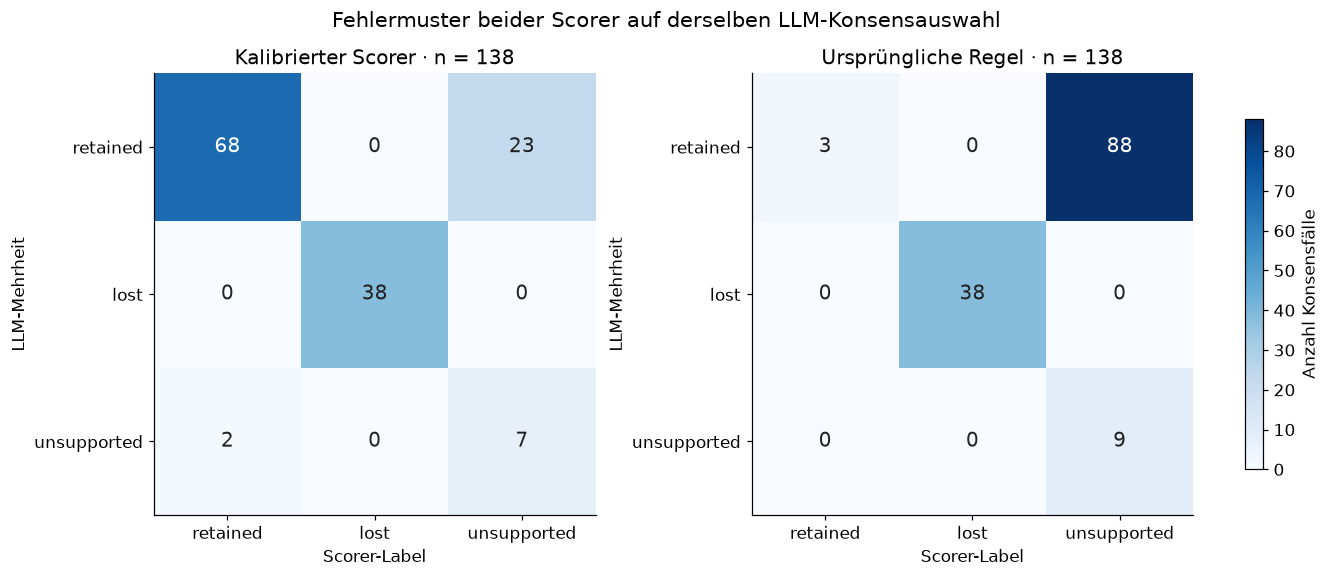

**Beobachtung:** Von den 91 Retained-Konsensfällen erkennt der kalibrierte Scorer 68, die ursprüngliche Regel 3 ebenfalls als Retained. Dies beschreibt die Übereinstimmung mit der LLM-Mehrheit.

In [12]:
fig,axes=plt.subplots(1,2,figsize=(12,5.2),layout='constrained')
vmax=max(np.array(estimates[s]['confusion_matrix']).max() for s in SCORERS)
comparison_matrix_rows=[]
for ax,scorer in zip(axes,SCORERS):
    matrix=np.asarray(estimates[scorer]['confusion_matrix'])
    im=ax.imshow(matrix,cmap='Blues',vmin=0,vmax=vmax)
    for i,truth in enumerate(LABELS):
        for j,pred in enumerate(LABELS):
            n=int(matrix[i,j])
            ax.text(j,i,str(n),ha='center',va='center',fontsize=13,color='white' if n>.55*vmax else '#222222')
            comparison_matrix_rows.append(dict(scorer=scorer,llm_majority=truth,scorer_label=pred,n=n))
    assert matrix.sum()==len(primary)
    ax.set(xticks=range(3),xticklabels=LABELS,yticks=range(3),yticklabels=LABELS,
           xlabel='Scorer-Label',ylabel='LLM-Mehrheit',
           title=('Kalibrierter Scorer' if scorer.startswith('calibrated') else 'Ursprüngliche Regel')+f' · n = {len(primary)}')
fig.colorbar(im,ax=axes,shrink=.7,label='Anzahl Konsensfälle')
fig.suptitle('Fehlermuster beider Scorer auf derselben LLM-Konsensauswahl',fontsize=14)
save_csv(comparison_matrix_rows,'grafik_konfusionsmatrizen_beide_scorer.csv')
save_figure(fig,'04_konfusionsmatrizen_beide_scorer.png')
retained_index=LABELS.index('retained')
display(Markdown('**Beobachtung:** Von den '+str(sum(estimates[SCORERS[0]]['confusion_matrix'][retained_index]))+
    ' Retained-Konsensfällen erkennt der kalibrierte Scorer '+str(estimates[SCORERS[0]]['confusion_matrix'][retained_index][retained_index])+
    ', die ursprüngliche Regel '+str(estimates[SCORERS[1]]['confusion_matrix'][retained_index][retained_index])+
    ' ebenfalls als Retained. Dies beschreibt die Übereinstimmung mit der LLM-Mehrheit.'))


### Ergänzende Grafik: Welche Klassen erkennt welcher Scorer?

Recall misst den Anteil der jeweiligen Mehrheitsklasse, den der Scorer wiedererkennt; Precision den Anteil seiner Klassenurteile, der mit der LLM-Mehrheit übereinstimmt. Die Balken sind die vorhandenen punktweisen 95-%-Artikelbootstrap-Intervalle. Die Recall-Beschriftungen nennen den Klassenumfang. Klassen ohne Referenzfälle bleiben ohne Recall-Punkt; ein nach bestehender Konvention auf null gesetzter Precision-Wert bei fehlenden Vorhersagen bleibt als solcher in der Tabelle dokumentiert.

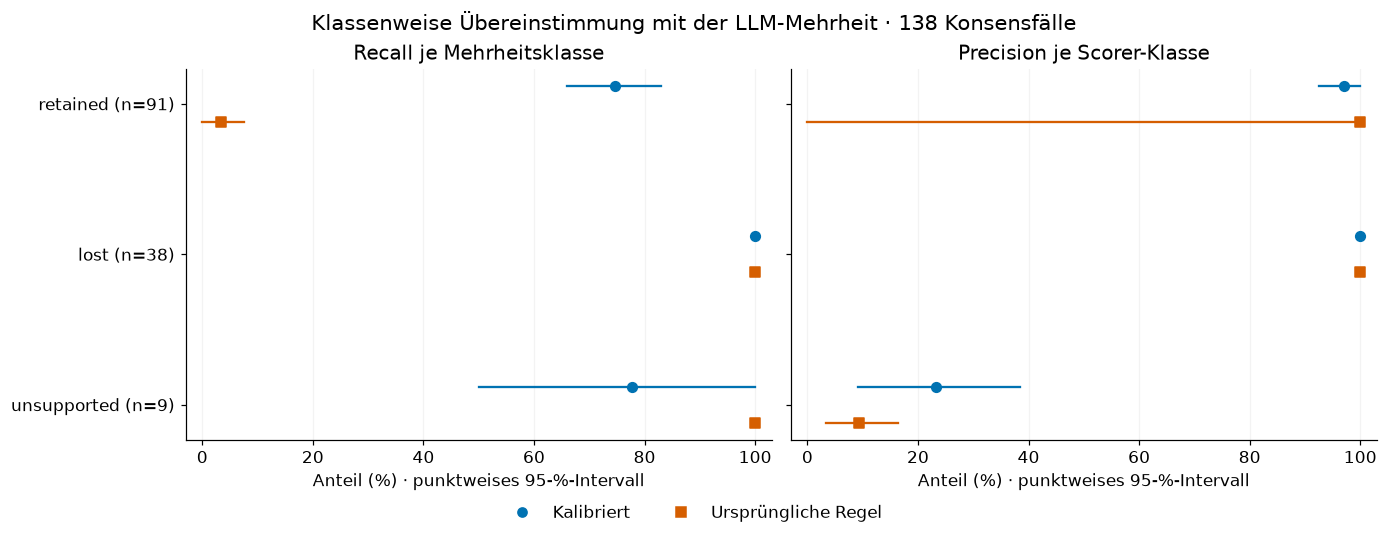

**Einordnung:** Die Klasse Unsupported umfasst nur 9 Referenzfälle. Insbesondere deren Recall und die Precision seltener Scorer-Urteile sind zusammen mit den breiten Intervallen und dem Klassenumfang zu lesen.

In [13]:
fig,axes=plt.subplots(1,2,figsize=(12.5,4.8),sharex=True,sharey=True,layout='constrained')
class_plot_rows=[]
for ax,metric,title in zip(axes,['recall','precision'],['Recall je Mehrheitsklasse','Precision je Scorer-Klasse']):
    for si,scorer in enumerate(SCORERS):
        color=['#0072B2','#D55E00'][si];marker=['o','s'][si]
        for i,item in enumerate(estimates[scorer]['per_class']):
            point=item[metric];ci=bootstrap['scorers'][scorer][item['label']+'.'+metric]
            y=i+[-.12,.12][si]
            if point is not None:
                ax.plot([ci['lower']*100,ci['upper']*100],[y,y],color=color,lw=1.5)
                ax.scatter(100*point,y,color=color,marker=marker,s=40,zorder=3)
            class_plot_rows.append(dict(scorer=scorer,label=item['label'],metric=metric,estimate=point,
                support=item['support'],predicted=item['predicted'],**ci))
    labels=[f'{item["label"]} (n={item["support"]})' for item in estimates[SCORERS[0]]['per_class']]
    ax.set(yticks=range(3),yticklabels=labels,xlim=(-3,103),xticks=range(0,101,20),
           xlabel='Anteil (%) · punktweises 95-%-Intervall',title=title)
    ax.grid(axis='x',alpha=.15)
axes[0].invert_yaxis()
fig.legend(handles=[plt.Line2D([0],[0],marker='o',color='#0072B2',ls='',label='Kalibriert'),
                    plt.Line2D([0],[0],marker='s',color='#D55E00',ls='',label='Ursprüngliche Regel')],
           loc='outside lower center',ncol=2,frameon=False)
fig.suptitle('Klassenweise Übereinstimmung mit der LLM-Mehrheit · 138 Konsensfälle',fontsize=14)
save_csv(class_plot_rows,'grafik_klassenmetriken_mit_intervallen.csv')
save_figure(fig,'05_precision_recall_beide_scorer.png')
display(Markdown('**Einordnung:** Die Klasse Unsupported umfasst nur '+
    str(estimates[SCORERS[0]]['per_class'][LABELS.index('unsupported')]['support'])+
    ' Referenzfälle. Insbesondere deren Recall und die Precision seltener Scorer-Urteile '
    'sind zusammen mit den breiten Intervallen und dem Klassenumfang zu lesen.'))
# Ergänzende CSV-Exporte aus dem ursprünglichen LLM-Auswertungsskript.
# Die Metrik- und Konsensfunktionen sind bereits unverändert im Referenznotebook.
for row in joined:
    row.update({p+'_comment':grouped[p][row['case_id']]['comment'] for p in pids})
exported=[]
for row in joined:
    out={k:v for k,v in row.items() if k!='three_class_consensus'}
    out['llm_main_class_majority']=row['three_class_consensus']
    for scorer in SCORERS:
        out[scorer+'_matches_llm_majority']=row[scorer]==row['consensus_label'] if row['three_class_consensus'] else ''
    exported.append(out)
save_csv(exported,'all_200_cases_llm_consensus.csv')
save_csv([r for r in exported if not r['llm_main_class_majority']],'excluded_special_or_tie.csv')
save_csv([r for r in exported if r['llm_main_class_majority'] and not r['calibrated_scorer_label_matches_llm_majority']],'calibrated_disagreements.csv')
common=[r for r in cases if all(grouped[p][r['case_id']]['human_label'] in LABELS for p in pids)]
individual=[]
for p in pids:
    for set_name,population in [('own_main_labels',[r for r in cases if grouped[p][r['case_id']]['human_label'] in LABELS]),('all_three_raters_main_labels',common)]:
        for scorer in SCORERS:
            m=metrics([grouped[p][r['case_id']]['human_label'] for r in population],[r[scorer] for r in population])
            individual.append(dict(rater_id=p,comparison_set=set_name,scorer=scorer,**{k:m[k] for k in ('n','correct','errors','accuracy','macro_f1','cohen_kappa')}))
save_csv(individual,'individual_scorer_comparisons.csv')
by_group=[]
for dimension in ('method','stage'):
    for value in sorted({r[dimension] for r in joined},key=str):
        sub=[r for r in primary if r[dimension]==value]
        for scorer in SCORERS:
            m=metrics([r['consensus_label'] for r in sub],[r[scorer] for r in sub])
            by_group.append(dict(dimension=dimension,value=value,scorer=scorer,**{k:m[k] for k in ('n','correct','errors','accuracy','macro_f1','cohen_kappa')}))
save_csv(by_group,'by_method_stage.csv')
save_csv([dict(rater_id=p,case_id=cid,llm_label=r['human_label'],comment=r['comment'],presentation_version=r.get('presentation_version','unrecorded')) for p in pids for cid,r in grouped[p].items()],'all_600_llm_judgments.csv')
save_csv([dict(rater_id=p,model_name_as_supplied=next(s['Modellangabe'] for s in source_rows if s['Rater']==p),**{k:sum(r['human_label']==k for r in grouped[p].values()) for k in HUMAN_LABELS}) for p in pids],'class_distributions.csv')


## 9. Einordnung für die Masterarbeit

Diese Zusatzanalyse zeigt eine hohe Konsistenz der drei vorliegenden LLM-Ausgaben und eine begrenzte Übereinstimmung des kalibrierten Scorers mit ihrer Hauptklassenmehrheit. Sie stützt keine Aussage über menschliche Reliabilität oder absolute faktische Wahrheit. Unterschiede zwischen Modellfamilien garantieren keine unabhängigen Fehler.

Die hohe Zahl an Sonderfallmehrheiten hängt mit dem gezielten schwierigen Material und den präziseren Klassenregeln zusammen. Sie darf nicht stillschweigend aus der Beschreibung der Stichprobe verschwinden. Hohe Lost-Übereinstimmung auf den verbleibenden Fällen beweist ebenso wenig vollständigen Faktenverlust im Hauptexperiment wie Unsupported eine Halluzination beweist.

Für eine belastbare unabhängige Human Validation sind weiterhin echte menschliche Urteile nötig. Für einen Jev-Vergleich fehlen die neuen Vorhersagen sowie ein überprüfbares Modell-/Laufprotokoll. Die hier verwendeten Modellnamen stammen aus den eingereichten Dateinamen; vollständige Prompts, Provider-Versionen und Laufparameter sind nicht mitgeliefert und wurden nicht erfunden.

**Abgrenzung der vier Notebooks:** interne Plausibilität (01), Robustheit unter Annahmen (02), bedingte Längenzusammenhänge (03) und modellbasierte Übereinstimmung (04) beleuchten unterschiedliche Grenzen derselben QA-Messung. Keine der vier Analysen ersetzt die jeweils anderen Kontrollen oder legitimiert eine nachträgliche Optimierung auf diesem Evaluationsmaterial.